<a href="https://colab.research.google.com/github/kvikaee/deep-learning/blob/main/%D0%93%D0%9E_%D0%9B%D0%A02_%D0%9A%D0%BE%D1%88%D1%83%D1%80%D0%B8%D0%BD%D0%B0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

В рамках этой лабораторной работы будут использоваться сверточные нейронные сети. Набор библиотек прежний, импортируйте все необходимые слои и т.п., задачи - классификация на изображениях.

In [ ]:
import os
import sys
import time
import glob
import subprocess
import importlib.util

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from IPython.display import display

from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import ResNet50, VGG16
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess
from tensorflow.keras.applications.vgg16 import preprocess_input as vgg_preprocess

np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))


TensorFlow: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


В первую очередь вернемся к MNIST и решим вё ту же задачу классификации изображений, используя сверточную архитектуру. Также допускается использование Dropout, pooling, flatten. Выходной слой - полносвязный. Значение точности выше 98% считается удовлетворительным для выполнения этого пункта. Постройте кривые обучения для обучающей и валидационной выборок.  

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - accuracy: 0.9209 - loss: 0.2606 - val_accuracy: 0.9833 - val_loss: 0.0591
Epoch 2/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9758 - loss: 0.0793 - val_accuracy: 0.9868 - val_loss: 0.0433
Epoch 3/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9825 - loss: 0.0572 - val_accuracy: 0.9885 - val_loss: 0.0388
Epoch 4/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9861 - loss: 0.0438 - val_accuracy: 0.9893 - val_loss: 0.0353
Epoch 5/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9887 - loss: 0.0364 - val_accuracy: 0.9912 - val_loss: 0.0325
Epoch 6/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9903 - loss: 0.0299 - val_accuracy: 0.9888 - val_loss: 0.0366
Epoch 7/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9918 - loss: 0.0268 - val_accuracy: 0.9902 - val_loss: 0.0389
Epoch 8/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9927 - loss: 0.0223 - val_accuracy: 0.9915 -

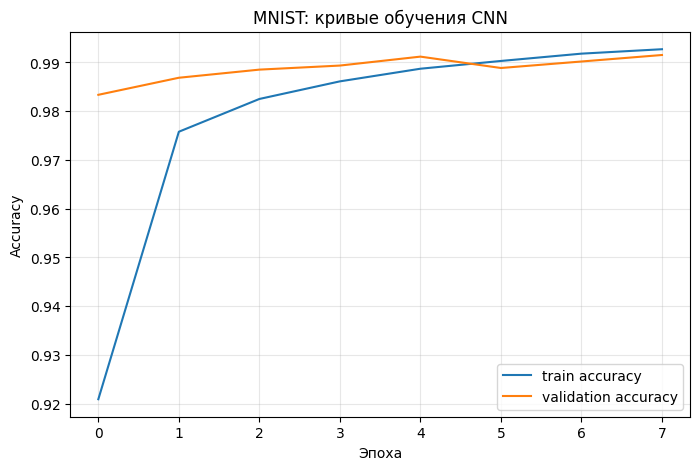

In [ ]:
# загружаем MNIST
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

# нормализуем изображения и добавляем размерность канала
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

x_train = x_train[..., np.newaxis]
x_test = x_test[..., np.newaxis]

mnist_cnn = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(10, activation="softmax")
])

mnist_cnn.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

mnist_cnn.summary()

history_mnist = mnist_cnn.fit(
    x_train,
    y_train,
    validation_split=0.1,
    epochs=8,
    batch_size=128,
    verbose=1
)

test_loss, test_accuracy = mnist_cnn.evaluate(x_test, y_test, verbose=0)
print(f"Точность на тестовой выборке: {test_accuracy:.4f}")

plt.figure(figsize=(8, 5))
plt.plot(history_mnist.history["accuracy"], label="train accuracy")
plt.plot(history_mnist.history["val_accuracy"], label="validation accuracy")
plt.xlabel("Эпоха")
plt.ylabel("Accuracy")
plt.title("MNIST: кривые обучения CNN")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


CNN быстро достигла высокой точности: около 99% на обучающей и валидационной выборках. Требование по точности выполнено, сильного переобучения не наблюдается.

Пока мы не отошли от MNIST, на этом же датасете обучите автоэнкодер, выходом которого должны быть картинки того же размера. Выведете несколько исходных картинок в паре с их обработанными вариантами по итогу обучения.

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 14, 14, 64)     │        36,928 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 28, 28, 32)     │        18,464 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 28, 28, 1)      │           289 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 74,497 (291.00 KB)

 Trainable params: 74,497 (291.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - loss: 0.1234 - val_loss: 0.0730
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.0702 - val_loss: 0.0693
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.0680 - val_loss: 0.0678
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - loss: 0.0668 - val_loss: 0.0668
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.0660 - val_loss: 0.0661
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - loss: 0.0654 - val_loss: 0.0656
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - loss: 0.0649 - val_loss: 0.0652
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - loss: 0.0645 - val_loss: 0.0648
Epoch 9/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.0642 - val_loss: 0.0646
Epoch 10/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.0639 - val_loss: 0.0643


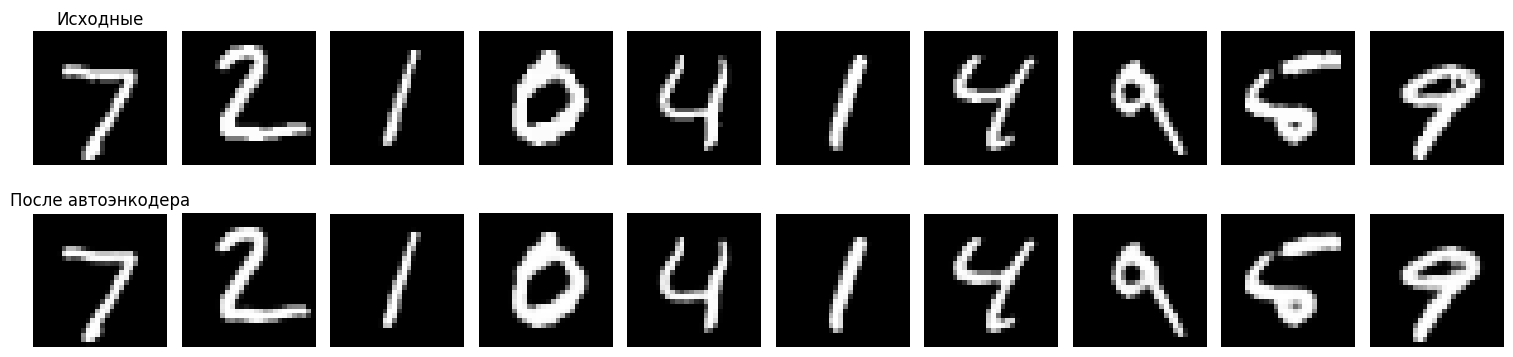

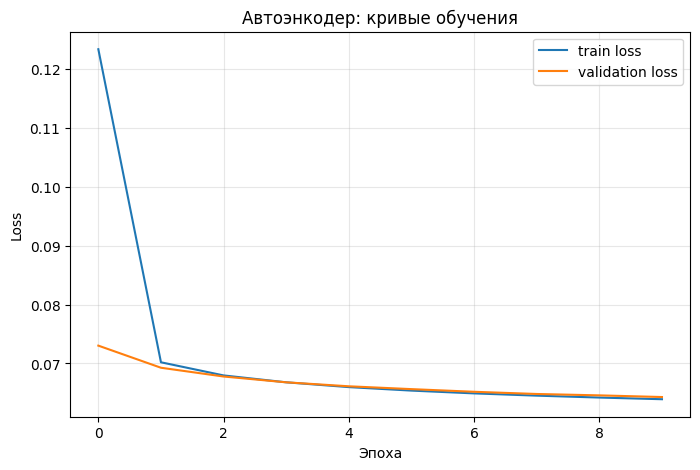

In [ ]:
# для автоэнкодера нужны только изображения
autoencoder = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),

    # encoder
    layers.Conv2D(32, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(2, padding="same"),
    layers.Conv2D(64, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(2, padding="same"),

    # decoder
    layers.Conv2DTranspose(64, 3, strides=2, activation="relu", padding="same"),
    layers.Conv2DTranspose(32, 3, strides=2, activation="relu", padding="same"),
    layers.Conv2D(1, 3, activation="sigmoid", padding="same")
])

autoencoder.compile(
    optimizer="adam",
    loss="binary_crossentropy"
)

autoencoder.summary()

history_autoencoder = autoencoder.fit(
    x_train,
    x_train,
    validation_split=0.1,
    epochs=10,
    batch_size=128,
    shuffle=True,
    verbose=1
)

reconstructed = autoencoder.predict(x_test[:10], verbose=0)

plt.figure(figsize=(15, 4))

for i in range(10):
    ax = plt.subplot(2, 10, i + 1)
    plt.imshow(x_test[i].squeeze(), cmap="gray")
    plt.axis("off")
    if i == 0:
        ax.set_title("Исходные")

    ax = plt.subplot(2, 10, i + 11)
    plt.imshow(reconstructed[i].squeeze(), cmap="gray")
    plt.axis("off")
    if i == 0:
        ax.set_title("После автоэнкодера")

plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(history_autoencoder.history["loss"], label="train loss")
plt.plot(history_autoencoder.history["val_loss"], label="validation loss")
plt.xlabel("Эпоха")
plt.ylabel("Loss")
plt.title("Автоэнкодер: кривые обучения")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


Loss быстро снижается и затем стабилизируется. Восстановленные изображения визуально близки к исходным, значит автоэнкодер успешно научился сжимать и восстанавливать изображения.

Теперь - задача бинарной классификации. Импортируйте датасет по ссылке: https://www.kaggle.com/datasets/tongpython/cat-and-dog. Можно загрузить его на google drive или же подгрузить прямо по ссылке с помощью библиотеки opendatasets. Выполните классификацию с помощью обычной сверточной сети, resnet50 (weights=None) и vgg16. Сравните динамику (на кривых обучения), скорость и конечные результаты обучения.

Using Colab cache for faster access to the 'cat-and-dog' dataset.
Train: /kaggle/input/cat-and-dog/training_set/training_set
Test: /kaggle/input/cat-and-dog/test_set/test_set
Found 8005 files belonging to 2 classes.
Using 6404 files for training.
Found 8005 files belonging to 2 classes.
Using 1601 files for validation.
Found 2023 files belonging to 2 classes.
Классы: ['cats', 'dogs']


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_2 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_6      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,569 (396.75 KB)

 Trainable params: 101,569 (396.75 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
201/201 ━━━━━━━━━━━━━━━━━━━━ 17s 69ms/step - accuracy: 0.5077 - loss: 0.6917 - val_accuracy: 0.5103 - val_loss: 0.6912
Epoch 2/5
201/201 ━━━━━━━━━━━━━━━━━━━━ 11s 54ms/step - accuracy: 0.5620 - loss: 0.6810 - val_accuracy: 0.6127 - val_loss: 0.6666
Epoch 3/5
201/201 ━━━━━━━━━━━━━━━━━━━━ 11s 55ms/step - accuracy: 0.5917 - loss: 0.6641 - val_accuracy: 0.6177 - val_loss: 0.6532
Epoch 4/5
201/201 ━━━━━━━━━━━━━━━━━━━━ 11s 56ms/step - accuracy: 0.6001 - loss: 0.6525 - val_accuracy: 0.6146 - val_loss: 0.6515
Epoch 5/5
201/201 ━━━━━━━━━━━━━━━━━━━━ 12s 59ms/step - accuracy: 0.6138 - loss: 0.6489 - val_accuracy: 0.6265 - val_loss: 0.6467
Обычная CNN:
  время обучения: 62.2 сек
  test accuracy: 0.6317


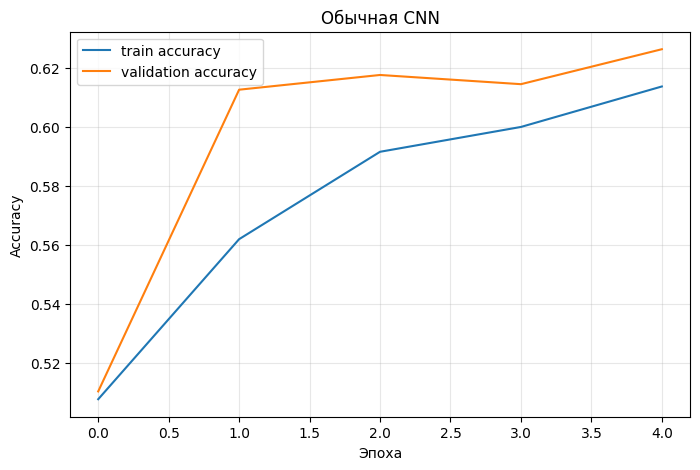

In [ ]:
if importlib.util.find_spec("kagglehub") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "kagglehub"])

import kagglehub

dataset_root = kagglehub.dataset_download("tongpython/cat-and-dog")


def find_split(root, split_name):
    for current, dirs, _ in os.walk(root):
        if os.path.basename(current) == split_name and {"cats", "dogs"}.issubset(set(dirs)):
            return current
    raise FileNotFoundError(f"Не найдена папка {split_name} с подпапками cats и dogs")

train_dir = find_split(dataset_root, "training_set")
test_dir = find_split(dataset_root, "test_set")

print("Train:", train_dir)
print("Test:", test_dir)

IMG_SIZE = (128, 128)
BATCH_SIZE = 32
SEED = 42
EPOCHS_CD = 5

train_ds = keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary"
)

val_ds = keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary"
)

test_ds = keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)

class_names = train_ds.class_names
print("Классы:", class_names)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

histories = {}
results = {}

def plot_history(history, title):
    plt.figure(figsize=(8, 5))
    plt.plot(history.history["accuracy"], label="train accuracy")
    plt.plot(history.history["val_accuracy"], label="validation accuracy")
    plt.xlabel("Эпоха")
    plt.ylabel("Accuracy")
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

def train_and_evaluate(model, name):
    start = time.perf_counter()

    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS_CD,
        verbose=1
    )

    elapsed = time.perf_counter() - start
    test_loss, test_accuracy = model.evaluate(test_ds, verbose=0)

    histories[name] = history
    results[name] = {
        "time_sec": elapsed,
        "test_accuracy": test_accuracy,
        "test_loss": test_loss
    }

    print(f"{name}:")
    print(f"  время обучения: {elapsed:.1f} сек")
    print(f"  test accuracy: {test_accuracy:.4f}")

    plot_history(history, name)
    return history

def build_simple_cnn():
    model = keras.Sequential([
        layers.Input(shape=(*IMG_SIZE, 3)),
        layers.Rescaling(1.0 / 255),
        layers.Conv2D(32, 3, activation="relu"),
        layers.MaxPooling2D(),
        layers.Conv2D(64, 3, activation="relu"),
        layers.MaxPooling2D(),
        layers.Conv2D(128, 3, activation="relu"),
        layers.MaxPooling2D(),
        layers.GlobalAveragePooling2D(),
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-4),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    return model

cnn_model = build_simple_cnn()
cnn_model.summary()
history_cnn = train_and_evaluate(cnn_model, "Обычная CNN")


Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 4, 4, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │         2,049 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,589,761 (89.99 MB)

 Trainable params: 23,536,641 (89.79 MB)

 Non-trainable params: 53,120 (207.50 KB)

Epoch 1/5
201/201 ━━━━━━━━━━━━━━━━━━━━ 115s 285ms/step - accuracy: 0.5336 - loss: 0.8582 - val_accuracy: 0.5003 - val_loss: 0.7069
Epoch 2/5
201/201 ━━━━━━━━━━━━━━━━━━━━ 27s 133ms/step - accuracy: 0.5801 - loss: 0.7870 - val_accuracy: 0.6040 - val_loss: 0.7209
Epoch 3/5
201/201 ━━━━━━━━━━━━━━━━━━━━ 28s 138ms/step - accuracy: 0.5940 - loss: 0.7600 - val_accuracy: 0.5578 - val_loss: 0.7727
Epoch 4/5
201/201 ━━━━━━━━━━━━━━━━━━━━ 41s 138ms/step - accuracy: 0.6052 - loss: 0.7330 - val_accuracy: 0.6052 - val_loss: 0.7057
Epoch 5/5
201/201 ━━━━━━━━━━━━━━━━━━━━ 27s 135ms/step - accuracy: 0.6338 - loss: 0.6930 - val_accuracy: 0.5709 - val_loss: 0.9095
ResNet50, weights=None:
  время обучения: 238.1 сек
  test accuracy: 0.5848


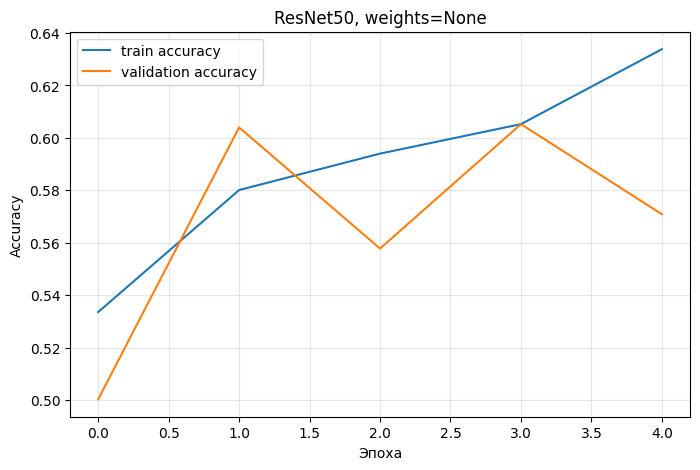

In [ ]:
def build_resnet(weights=None, augmentation=None):
    inputs = keras.Input(shape=(*IMG_SIZE, 3))
    x = inputs

    if augmentation is not None:
        x = augmentation(x)

    x = layers.Lambda(resnet_preprocess)(x)

    base_model = ResNet50(
        weights=weights,
        include_top=False,
        input_shape=(*IMG_SIZE, 3)
    )

    x = base_model(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)

    model = keras.Model(inputs, outputs)

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-4),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    return model

resnet_model = build_resnet(weights=None)
resnet_model.summary()
history_resnet = train_and_evaluate(resnet_model, "ResNet50, weights=None")


Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda_1 (Lambda)               │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 4, 4, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,715,201 (56.13 MB)

 Trainable params: 14,715,201 (56.13 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
201/201 ━━━━━━━━━━━━━━━━━━━━ 86s 289ms/step - accuracy: 0.5403 - loss: 0.6850 - val_accuracy: 0.5222 - val_loss: 0.7316
Epoch 2/5
201/201 ━━━━━━━━━━━━━━━━━━━━ 40s 197ms/step - accuracy: 0.5926 - loss: 0.6627 - val_accuracy: 0.6296 - val_loss: 0.6512
Epoch 3/5
201/201 ━━━━━━━━━━━━━━━━━━━━ 42s 208ms/step - accuracy: 0.6157 - loss: 0.6432 - val_accuracy: 0.6327 - val_loss: 0.6328
Epoch 4/5
201/201 ━━━━━━━━━━━━━━━━━━━━ 40s 199ms/step - accuracy: 0.6627 - loss: 0.6189 - val_accuracy: 0.5403 - val_loss: 0.6520
Epoch 5/5
201/201 ━━━━━━━━━━━━━━━━━━━━ 40s 200ms/step - accuracy: 0.6819 - loss: 0.5951 - val_accuracy: 0.7058 - val_loss: 0.5791
VGG16, weights=None:
  время обучения: 247.8 сек
  test accuracy: 0.7039


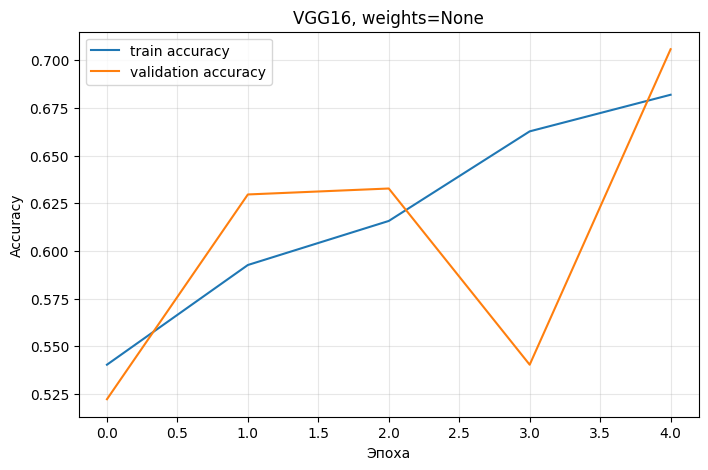

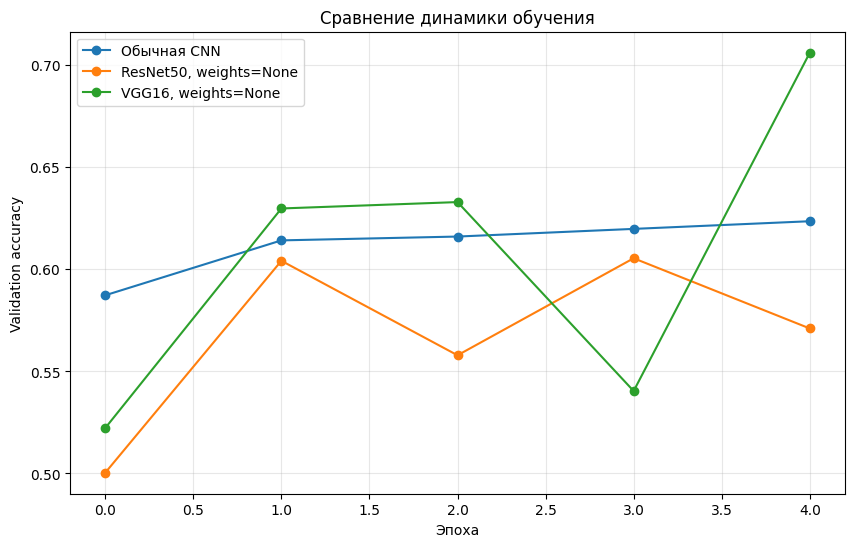

,time_sec,test_accuracy,test_loss
Обычная CNN,49.7847,0.6337,0.6428
"ResNet50, weights=None",238.1105,0.5848,0.8586
"VGG16, weights=None",247.8490,0.7039,0.5780


Лучшая точность среди первых трех моделей: VGG16, weights=None
Самое быстрое обучение среди первых трех моделей: Обычная CNN


In [ ]:
def build_vgg16():
    inputs = keras.Input(shape=(*IMG_SIZE, 3))
    x = layers.Lambda(vgg_preprocess)(inputs)

    base_model = VGG16(
        weights=None,
        include_top=False,
        input_shape=(*IMG_SIZE, 3)
    )

    x = base_model(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)

    model = keras.Model(inputs, outputs)

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-4),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    return model

vgg_model = build_vgg16()
vgg_model.summary()
history_vgg = train_and_evaluate(vgg_model, "VGG16, weights=None")

# сравниваем динамику трех моделей на одном графике
plt.figure(figsize=(10, 6))

for name in ["Обычная CNN", "ResNet50, weights=None", "VGG16, weights=None"]:
    history = histories[name]
    plt.plot(history.history["val_accuracy"], marker="o", label=name)

plt.xlabel("Эпоха")
plt.ylabel("Validation accuracy")
plt.title("Сравнение динамики обучения")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

comparison_first = pd.DataFrame(results).T
comparison_first = comparison_first.loc[
    ["Обычная CNN", "ResNet50, weights=None", "VGG16, weights=None"]
]
display(comparison_first.round(4))

best_first = comparison_first["test_accuracy"].idxmax()
fastest_first = comparison_first["time_sec"].idxmin()

print("Лучшая точность среди первых трех моделей:", best_first)
print("Самое быстрое обучение среди первых трех моделей:", fastest_first)


Лучший результат показала VGG16 - 70,39%, обычная CNN - 63,37%, ResNet50 - 58,48%. При этом обычная CNN обучилась значительно быстрее остальных моделей.

Теперь остановимся на архитектуре, включающей в себя resnet, и рассмотрим два способа дополнения обычной модели. Во-первых, можно аугментировать данные. Ознакомьтесь со слоями аугментации (https://keras.io/api/layers/preprocessing_layers/image_augmentation/) и обучите модель уже на модифицированных изображениях с нуля, но с сохранением той же архитектуры и тех же параметров обучения. Сравните с исходным результатом. (Ссылка для pytorch: https://pytorch.org/vision/stable/transforms.html)

Model: "functional_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda_2 (Lambda)               │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 4, 4, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │         2,049 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,589,761 (89.99 MB)

 Trainable params: 23,536,641 (89.79 MB)

 Non-trainable params: 53,120 (207.50 KB)

Epoch 1/5
201/201 ━━━━━━━━━━━━━━━━━━━━ 90s 250ms/step - accuracy: 0.5433 - loss: 0.8382 - val_accuracy: 0.4909 - val_loss: 0.8063
Epoch 2/5
201/201 ━━━━━━━━━━━━━━━━━━━━ 47s 235ms/step - accuracy: 0.5628 - loss: 0.8284 - val_accuracy: 0.5097 - val_loss: 0.9034
Epoch 3/5
201/201 ━━━━━━━━━━━━━━━━━━━━ 48s 237ms/step - accuracy: 0.5857 - loss: 0.7579 - val_accuracy: 0.5259 - val_loss: 1.7924
Epoch 4/5
201/201 ━━━━━━━━━━━━━━━━━━━━ 48s 238ms/step - accuracy: 0.6057 - loss: 0.7359 - val_accuracy: 0.6515 - val_loss: 0.7145
Epoch 5/5
201/201 ━━━━━━━━━━━━━━━━━━━━ 81s 233ms/step - accuracy: 0.6156 - loss: 0.7266 - val_accuracy: 0.6052 - val_loss: 1.0058
ResNet50 + augmentation:
  время обучения: 348.4 сек
  test accuracy: 0.5907


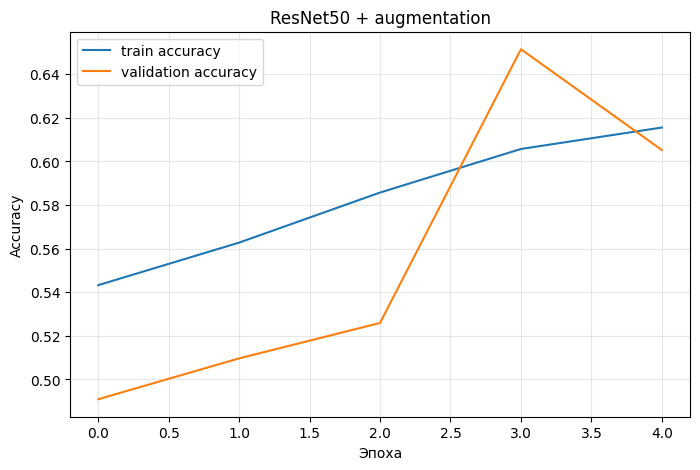

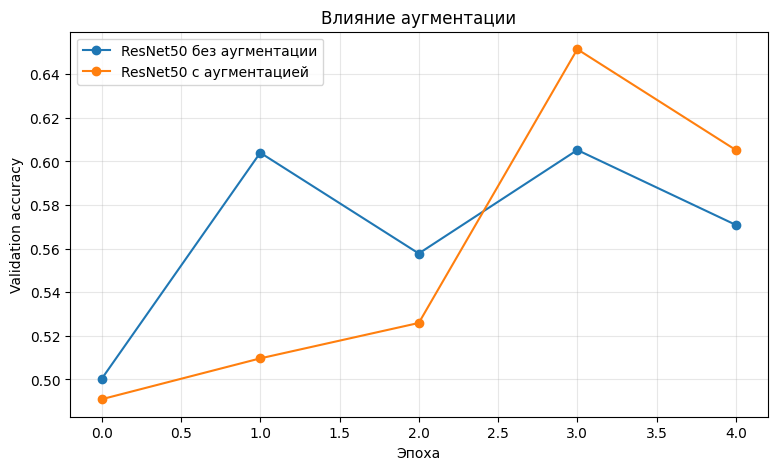

,time_sec,test_accuracy,test_loss
"ResNet50, weights=None",238.1105,0.5848,0.8586
ResNet50 + augmentation,348.3848,0.5907,1.0359


In [ ]:
# аугментация применяется только во время обучения
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1)
], name="augmentation")

resnet_aug_model = build_resnet(
    weights=None,
    augmentation=data_augmentation
)

resnet_aug_model.summary()
history_resnet_aug = train_and_evaluate(
    resnet_aug_model,
    "ResNet50 + augmentation"
)

plt.figure(figsize=(9, 5))
plt.plot(
    histories["ResNet50, weights=None"].history["val_accuracy"],
    marker="o",
    label="ResNet50 без аугментации"
)
plt.plot(
    histories["ResNet50 + augmentation"].history["val_accuracy"],
    marker="o",
    label="ResNet50 с аугментацией"
)
plt.xlabel("Эпоха")
plt.ylabel("Validation accuracy")
plt.title("Влияние аугментации")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

comparison_aug = pd.DataFrame(results).T.loc[
    ["ResNet50, weights=None", "ResNet50 + augmentation"]
]
display(comparison_aug.round(4))


Добавление аугментации немного повысило результат ResNet50 с 58,48% до 59,07%, но также заметно увеличило время обучения. За 5 эпох существенного улучшения качества не произошло.

Наконец, используйте перенос обучения. Для этого достаточно просто установить параметр weights='imagenet'. Перенос обучения позволяет установить веса в начале обучения определенным образом вместо рандомной инициализации, в данном случае используются веса resnet50, обученного на датасете imagenet. Точно также обучите сеть, сохраняя все остальные параметры, на немодифицированных данных, и сравните результаты.

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


Model: "functional_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_10 (InputLayer)     │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda_3 (Lambda)               │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 4, 4, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_4      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │         2,049 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,589,761 (89.99 MB)

 Trainable params: 23,536,641 (89.79 MB)

 Non-trainable params: 53,120 (207.50 KB)

Epoch 1/5
201/201 ━━━━━━━━━━━━━━━━━━━━ 103s 261ms/step - accuracy: 0.9218 - loss: 0.1867 - val_accuracy: 0.9544 - val_loss: 0.2016
Epoch 2/5
201/201 ━━━━━━━━━━━━━━━━━━━━ 27s 133ms/step - accuracy: 0.9908 - loss: 0.0296 - val_accuracy: 0.9706 - val_loss: 0.0838
Epoch 3/5
201/201 ━━━━━━━━━━━━━━━━━━━━ 42s 137ms/step - accuracy: 0.9866 - loss: 0.0414 - val_accuracy: 0.9582 - val_loss: 0.1546
Epoch 4/5
201/201 ━━━━━━━━━━━━━━━━━━━━ 28s 140ms/step - accuracy: 0.9944 - loss: 0.0185 - val_accuracy: 0.9575 - val_loss: 0.1419
Epoch 5/5
201/201 ━━━━━━━━━━━━━━━━━━━━ 29s 142ms/step - accuracy: 0.9973 - loss: 0.0102 - val_accuracy: 0.9582 - val_loss: 0.1373
ResNet50, ImageNet:
  время обучения: 228.4 сек
  test accuracy: 0.9580


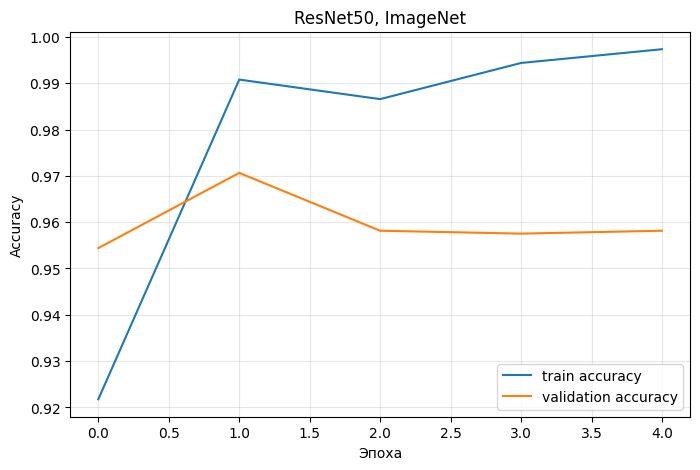

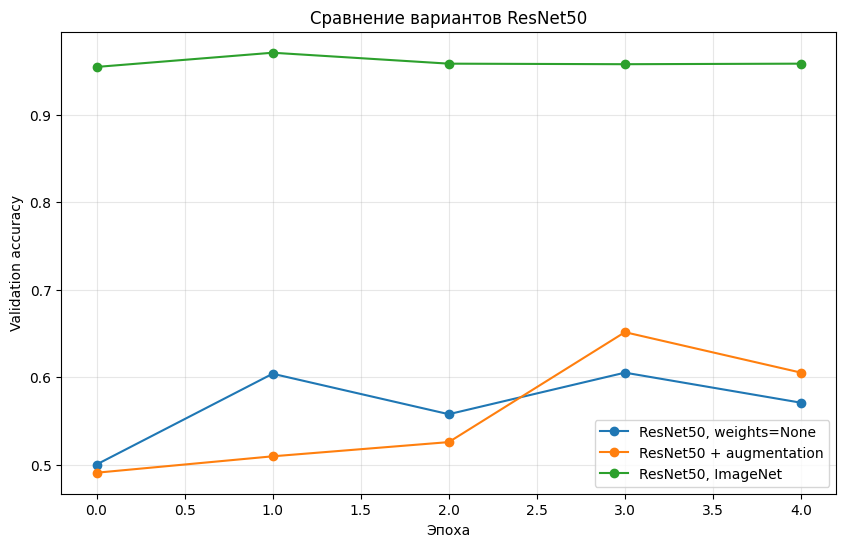

,time_sec,test_accuracy,test_loss
"ResNet50, ImageNet",228.4287,0.9580,0.1392
"VGG16, weights=None",247.8490,0.7039,0.5780
Обычная CNN,49.7847,0.6337,0.6428
ResNet50 + augmentation,348.3848,0.5907,1.0359
"ResNet50, weights=None",238.1105,0.5848,0.8586


Максимальная точность на тесте: ResNet50, ImageNet
Минимальное время обучения: Обычная CNN

Вывод по ResNet50:
После запуска таблица и график выше позволяют сравнить обычное обучение с нуля, аугментацию и перенос весов ImageNet по точности, динамике и времени обучения.


In [ ]:
# архитектура и параметры обучения остаются теми же,
# меняется только начальная инициализация весов ResNet50
resnet_imagenet_model = build_resnet(
    weights="imagenet",
    augmentation=None
)

resnet_imagenet_model.summary()
history_resnet_imagenet = train_and_evaluate(
    resnet_imagenet_model,
    "ResNet50, ImageNet"
)

plt.figure(figsize=(10, 6))

for name in [
    "ResNet50, weights=None",
    "ResNet50 + augmentation",
    "ResNet50, ImageNet"
]:
    plt.plot(
        histories[name].history["val_accuracy"],
        marker="o",
        label=name
    )

plt.xlabel("Эпоха")
plt.ylabel("Validation accuracy")
plt.title("Сравнение вариантов ResNet50")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

final_comparison = pd.DataFrame(results).T.sort_values(
    "test_accuracy",
    ascending=False
)

display(final_comparison.round(4))

best_model = final_comparison["test_accuracy"].idxmax()
fastest_model = final_comparison["time_sec"].idxmin()

print(f"Максимальная точность на тесте: {best_model}")
print(f"Минимальное время обучения: {fastest_model}")

resnet_comparison = final_comparison.loc[
    [
        "ResNet50, weights=None",
        "ResNet50 + augmentation",
        "ResNet50, ImageNet"
    ]
]

print("\nВывод по ResNet50:")
print(
    "После запуска таблица и график выше позволяют сравнить "
    "обычное обучение с нуля, аугментацию и перенос весов ImageNet "
    "по точности, динамике и времени обучения."
)


Использование предобученных весов резко повысило точность до 95,8% и уменьшило test loss до 0,1392. Это значительно лучше обучения ResNet50 с нуля.

### Итог

В работе используются сверточные сети для MNIST и бинарной классификации кошек и собак. Для MNIST строятся CNN и автоэнкодер. Для Cats vs Dogs сравниваются обычная CNN, ResNet50 и VGG16, после чего отдельно исследуется влияние аугментации и предобученных весов ImageNet на ResNet50.

Предобученная ResNet50 показала лучший результат среди всех моделей. Transfer learning оказался намного эффективнее обучения больших нейросетей с нуля на данном датасете.
